# D · Tipología territorial de AGEB urbanas para el programa de cuidado (CDMX)

*Sección 18 · segundo modelo de la UCA Herramientas y Técnicas Avanzadas · creado 2026-10-09*

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/
```

### Para qué decisión existe

El programa elegido el 5 oct 2026 (opción C) ofrece relevo por horas a la persona cuidadora familiar de alta
intensidad, con una app de dos perfiles. Antes del piloto hay que decidir **en qué tipo de zona de la CDMX se
prueba** y **qué zonas quedan fuera de lo que el piloto puede demostrar**. El modelo 11 (notebook B) responde *a
quién* ofrecer el relevo, pero con datos nacionales; no dice nada del territorio.

Este notebook construye una **tipología de AGEB urbanas** con datos del Censo 2020, la compara contra alternativas
simples y le sobrepone la oferta de cuidado del DENUE. El resultado sirve para tres cosas concretas:

1. **Estratificar** la elección de la sede del piloto: saber a qué tipo de zona pertenece una sede candidata y,
   por lo tanto, a qué parte de la ciudad se pueden extrapolar (y a cuál no) sus resultados.
2. **Revisar el canal**: la app supone internet en la vivienda; la tipología muestra dónde ese supuesto falla.
3. **Ubicar brechas**: zonas con mucha población de 60 años y más y lejos de la oferta formal de cuidado.

### Qué representa una fila

| Fuente | Unidad | Clave | Año | Notas |
|---|---|---|---|---|
| Censo 2020, *Principales resultados por AGEB y manzana urbana*, CDMX (`datos/censo2020_ageb/`) | AGEB urbana (filas con `MZA = 000`) | `CVEGEO` = entidad + municipio + localidad + AGEB (13 caracteres) | 2020 | Conteo censal, sin factor de expansión. INEGI suprime con `*` en AGEB con muy pocas viviendas |
| CONEVAL, grado de rezago social por AGEB 2020 (`datos/coneval_irs/`) | AGEB urbana | `folio_ageb` = `CVEGEO` | 2020 | Solo para **validación externa**: no entra al modelo |
| Marco Geoestadístico 2025, INEGI (`datos/marco_geo_2025/`) | Polígono de AGEB urbana y de alcaldía | `CVEGEO` | 2025 | Geometría para vecindad, distancias y mapas |
| DENUE 05_2026 (`Data/raw/denue_inegi_09_.csv`) | Establecimiento | `codigo_act` SCIAN | 2026 | Oferta **núcleo** de cuidado (catálogo `catalogo_scian_cuidado.csv`, mismo criterio que la sección 01) |

Las AGEB **no son observaciones independientes**: las vecinas se parecen entre sí (se mide en la sección 8).

### Qué NO permite este notebook

- **No mide necesidad de cuidado individual.** Son proporciones por zona: que una AGEB tenga mucha población de 60+
  no dice que esas personas necesiten cuidado ni que alguien las cuide (falacia ecológica).
- **No dice dónde funciona el relevo.** Eso solo lo puede mostrar el piloto.
- **No sustituye a la ENASIC.** La ENASIC no baja a alcaldía; el Censo no pregunta por cuidado. Este modelo no
  combina ambas fuentes a nivel persona.
- **No es una serie.** Censo 2020 (año de pandemia) y DENUE 2026 son cortes únicos y de fechas distintas.

In [1]:
from pathlib import Path
import zipfile, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

from estilo_graficas import estilo, nota, AZUL, NARANJA, AQUA, AMARILLO, GRIS, TINTA, TENUE, REJILLA
estilo()
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 70)

DATOS = Path('datos'); OUT = Path('resultados'); FIG = Path('figuras')
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
DENUE = Path('..') / 'Data' / 'raw' / 'denue_inegi_09_.csv'
SEMILLA = 20261009
rng = np.random.default_rng(SEMILLA)

## 1. Carga, unión de fuentes y control de calidad

Se verifica el archivo del Censo por su SHA-256 (registrado en `datos/censo2020_ageb/FUENTE.txt`) y se reconstruyen
los totales antes de usar cualquier variable.

In [2]:
import hashlib
ZIP_CENSO = DATOS / 'censo2020_ageb' / 'ageb_mza_urbana_09_cpv2020_csv.zip'
sha = hashlib.sha256(ZIP_CENSO.read_bytes()).hexdigest()
assert sha == '1f5f123b8e9a50991d1847271b5a2bf321e813e924e5bcf958cab612311c765a', 'El archivo del Censo no es el registrado'

with zipfile.ZipFile(ZIP_CENSO) as z:
    censo = pd.read_csv(z.open('ageb_mza_urbana_09_cpv2020/conjunto_de_datos/conjunto_de_datos_ageb_urbana_09_cpv2020.csv'), dtype=str)
total_entidad = int(censo.loc[(censo.MUN == '000'), 'POBTOT'].iloc[0])
ageb = censo[(censo.MZA == '000') & (censo.AGEB != '0000') & (censo.LOC != '0000')].copy()
ageb['CVEGEO'] = ageb.ENTIDAD + ageb.MUN + ageb.LOC + ageb.AGEB
assert ageb.CVEGEO.is_unique
ageb['POBTOT'] = ageb.POBTOT.astype(int)
print(f'Población total CDMX (Censo 2020): {total_entidad:,}')
print(f'AGEB urbanas: {len(ageb):,} | población en AGEB urbanas: {ageb.POBTOT.sum():,} ({100*ageb.POBTOT.sum()/total_entidad:.1f} %)')

with zipfile.ZipFile(DATOS / 'coneval_irs' / 'grs_ageb_2020.csv.zip') as z:
    grs = pd.read_csv(z.open('grs_ageb_2020.csv'), dtype=str, usecols=['clave_entidad', 'folio_ageb', 'grs'])
grs = grs[grs.clave_entidad == '9'].rename(columns={'folio_ageb': 'CVEGEO'})[['CVEGEO', 'grs']]

geo = gpd.read_file(DATOS / 'marco_geo_2025' / '09a.shp')[['CVEGEO', 'geometry']]
alc_geo = gpd.read_file(DATOS / 'marco_geo_2025' / '09mun.shp')
print(f'Polígonos de AGEB urbana (Marco 2025): {len(geo):,} | CRS: {geo.crs.name}')

Población total CDMX (Censo 2020): 9,209,944
AGEB urbanas: 2,433 | población en AGEB urbanas: 9,145,632 (99.3 %)


Polígonos de AGEB urbana (Marco 2025): 2,430 | CRS: MEXICO_ITRF_2008_LCC


**Variables del modelo.** Nueve indicadores en tres bloques, todos calculables con el Censo por AGEB y todos con una
razón ligada a la decisión. Se fijaron **antes** de ver resultados; las alternativas se prueban en la sección 7.

| Bloque | Variable | Cálculo (Censo 2020) | Por qué importa para el relevo |
|---|---|---|---|
| Demanda de cuidado | `pct_60` | `P_60YMAS / POBTOT` | Población que más probablemente requiere cuidado |
| | `pct_disc` | `PCON_DISC / POBTOT` | Discapacidad (mucha dificultad o no puede), cualquier edad |
| | `pct_0a14` | `POB0_14 / POBTOT` | Carga simultánea de cuidado infantil; en el modelo 11, cuidar además a menores se asocia con más daño |
| Disponibilidad de cuidadoras en el hogar | `prom_ocup` | `PROM_OCUP` | Hogares más chicos, menos personas para repartir el cuidado |
| | `part_fem` | `PEA_F / P_12YMAS_F` | Mujeres en el mercado laboral: menos tiempo disponible para cuidar sin pago |
| | `pct_jef_f` | `HOGJEF_F / TOTHOG` | Hogares con jefatura femenina |
| Capacidad de pago y acceso | `pct_sinder` | `PSINDER / POBTOT` | Sin afiliación a servicios de salud |
| | `graproes` | `GRAPROES` | Escolaridad promedio (aproximación a ingreso, que el Censo no capta) |
| | `pct_sin_int` | `1 − VPH_INTER / VIVPARH_CV` | Viviendas sin internet: **canal de la app** |

**Regla de exclusión** (fijada antes de modelar): AGEB con menos de 100 habitantes o con algún indicador suprimido.
Con tan poca población, un porcentaje cambia mucho con una persona y el INEGI suprime datos por confidencialidad.

In [3]:
def num(col):
    return pd.to_numeric(ageb[col], errors='coerce')

VARS = ['pct_60', 'pct_disc', 'pct_0a14', 'prom_ocup', 'part_fem', 'pct_jef_f', 'pct_sinder', 'graproes', 'pct_sin_int']
BLOQUE = {'pct_60': 'Demanda', 'pct_disc': 'Demanda', 'pct_0a14': 'Demanda', 'prom_ocup': 'Cuidadoras', 'part_fem': 'Cuidadoras',
          'pct_jef_f': 'Cuidadoras', 'pct_sinder': 'Capacidad', 'graproes': 'Capacidad', 'pct_sin_int': 'Capacidad'}
ETQ = {'pct_60': '% 60 años y más', 'pct_disc': '% con discapacidad', 'pct_0a14': '% de 0 a 14 años',
       'prom_ocup': 'Ocupantes por vivienda', 'part_fem': '% mujeres 12+ económicamente activas', 'pct_jef_f': '% hogares con jefa',
       'pct_sinder': '% sin afiliación a salud', 'graproes': 'Escolaridad promedio (años)', 'pct_sin_int': '% viviendas sin internet'}

ageb = ageb.assign(
    pct_60=100 * num('P_60YMAS') / ageb.POBTOT, pct_disc=100 * num('PCON_DISC') / ageb.POBTOT, pct_0a14=100 * num('POB0_14') / ageb.POBTOT,
    prom_ocup=num('PROM_OCUP'), part_fem=100 * num('PEA_F') / num('P_12YMAS_F'), pct_jef_f=100 * num('HOGJEF_F') / num('TOTHOG'),
    pct_sinder=100 * num('PSINDER') / ageb.POBTOT, graproes=num('GRAPROES'), pct_sin_int=100 * (1 - num('VPH_INTER') / num('VIVPARH_CV')),
    n_60=num('P_60YMAS'), n_disc=num('PCON_DISC'), pct_limi=100 * num('PCON_LIMI') / ageb.POBTOT,
    viv=num('VIVPARH_CV'), viv_sin_int=num('VIVPARH_CV') - num('VPH_INTER'), n_sinder=num('PSINDER'))
ageb = ageb.rename(columns={'NOM_MUN': 'alcaldia'})

excl_pob = ageb.POBTOT < 100
excl_na = ageb[VARS].isna().any(axis=1) & ~excl_pob
d = ageb[~excl_pob & ~excl_na].copy().reset_index(drop=True)
d = d.merge(grs, on='CVEGEO', how='left', validate='one_to_one')

calidad = pd.DataFrame([
    ('AGEB urbanas en el Censo 2020', len(ageb), ageb.POBTOT.sum()),
    ('Excluidas: menos de 100 habitantes', excl_pob.sum(), ageb.loc[excl_pob, 'POBTOT'].sum()),
    ('Excluidas: algún indicador suprimido o no calculable', excl_na.sum(), ageb.loc[excl_na, 'POBTOT'].sum()),
    ('AGEB en el modelo', len(d), d.POBTOT.sum()),
    ('  ... con grado de rezago CONEVAL', d.grs.notna().sum(), d.loc[d.grs.notna(), 'POBTOT'].sum()),
    ('  ... con polígono en el Marco 2025', d.CVEGEO.isin(geo.CVEGEO).sum(), d.loc[d.CVEGEO.isin(geo.CVEGEO), 'POBTOT'].sum()),
], columns=['chequeo', 'n_ageb', 'poblacion'])
calidad['pct_poblacion_cdmx'] = (100 * calidad.poblacion / total_entidad).round(2)
assert (d[VARS].notna().all().all()) and len(d) > 2300
calidad

,chequeo,n_ageb,poblacion,pct_poblacion_cdmx
0,AGEB urbanas en el Censo 2020,2433,9145632,99.30
1,Excluidas: menos de 100 habitantes,55,1302,0.01
2,Excluidas: algún indicador suprimido o no calculable,5,9332,0.10
3,AGEB en el modelo,2373,9134998,99.19
4,... con grado de rezago CONEVAL,2371,9127890,99.11
5,... con polígono en el Marco 2025,2371,9127890,99.11


Distribución de las nueve variables en las AGEB del modelo. Ninguna tiene valores imposibles (todas las
proporciones entre 0 y 100), pero hay colas: `part_fem` llega a 96 % en AGEB pequeñas y atípicas, y `pct_sin_int`
va de casi 0 a 80 %. Por eso la sección 7 repite el modelo con un escalamiento robusto a atípicos.

In [4]:
assert d[[v for v in VARS if v.startswith('pct') or v == 'part_fem']].apply(lambda s: s.between(0, 100)).all().all()
d[VARS].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max
pct_60,2373.0,17.47,5.84,1.04,8.78,13.23,16.81,21.27,27.84,41.87
pct_disc,2373.0,5.41,1.78,0.47,2.72,4.24,5.32,6.44,8.30,18.50
pct_0a14,2373.0,17.11,4.67,3.13,9.88,13.39,17.15,20.35,24.86,33.19
prom_ocup,2373.0,3.34,0.51,1.77,2.41,2.99,3.41,3.72,4.05,5.59
part_fem,2373.0,55.42,6.04,20.96,46.98,51.64,54.68,58.59,66.26,95.69
pct_jef_f,2373.0,39.97,5.68,9.14,30.78,36.40,40.22,43.56,48.86,62.61
pct_sinder,2373.0,26.61,6.93,0.94,16.25,22.19,26.23,30.69,38.30,59.48
graproes,2373.0,11.71,1.77,1.05,9.27,10.38,11.41,13.17,14.84,16.15
pct_sin_int,2373.0,24.06,12.40,0.22,5.41,14.40,24.42,31.86,44.22,80.23


## 2. Oferta de cuidado del DENUE: distancia a la oferta núcleo

Se usan los cuatro códigos **núcleo** del catálogo (residencias y centros de día, públicos y privados), el mismo
criterio de la sección 01, que reportó 235 establecimientos. Para cada AGEB se calcula la distancia en línea recta
desde su centroide hasta el establecimiento núcleo más cercano. **No es tiempo de traslado** ni mide capacidad
(plazas) ni precio. La oferta **no entra al modelo**: se sobrepone después, para no mezclar quién vive en la
zona con qué servicios hay.

In [5]:
cat = pd.read_csv('catalogo_scian_cuidado.csv', dtype=str)
nucleo = set(cat.loc[cat.grupo == 'nucleo', 'codigo_act'])
den = pd.concat(ch[ch.codigo_act.isin(nucleo)] for ch in pd.read_csv(DENUE, encoding='latin-1', dtype=str, chunksize=300_000,
                usecols=['id', 'codigo_act', 'nombre_act', 'latitud', 'longitud']))
den = gpd.GeoDataFrame(den, geometry=gpd.points_from_xy(den.longitud.astype(float), den.latitud.astype(float)), crs=4326).to_crs(geo.crs)
print('Establecimientos núcleo:', len(den), '(sección 01: 235)')
assert len(den) == 235

g = geo.merge(d, on='CVEGEO', how='inner', validate='one_to_one').reset_index(drop=True)
cent = g.geometry.centroid
arbol = cKDTree(np.c_[den.geometry.x, den.geometry.y])
dist_m, _ = arbol.query(np.c_[cent.x, cent.y])
g['dist_oferta_km'] = dist_m / 1000
g['n_oferta_2km'] = [len(x) for x in arbol.query_ball_point(np.c_[cent.x, cent.y], r=2000)]
print(f'AGEB con geometría: {len(g):,} de {len(d):,}. Sin polígono en el Marco 2025:',
      sorted(set(d.CVEGEO) - set(g.CVEGEO)))
g['dist_oferta_km'].describe().round(2)

Establecimientos núcleo: 235 (sección 01: 235)
AGEB con geometría: 2,371 de 2,373. Sin polígono en el Marco 2025: ['0901101101107', '0901201351227']


count    2371.00
mean        1.04
std         0.79
min         0.01
25%         0.53
50%         0.88
75%         1.35
max         7.66
Name: dist_oferta_km, dtype: float64

A partir de aquí se trabaja con las AGEB que tienen polígono (todas menos las listadas arriba, que existen en el
Censo 2020 pero cambiaron de clave en el Marco 2025).

## 3. Estandarización y estructura de las variables (PCA)

Las variables tienen escalas distintas (años, porcentajes, personas por vivienda), así que se estandarizan
(media 0, desviación 1). El análisis de componentes principales no es el modelo: sirve para ver **cuántas
dimensiones independientes** hay en los datos antes de agruparlos.

In [6]:
X = g[VARS].to_numpy(float)
Z = StandardScaler().fit_transform(X)
pca = PCA(random_state=SEMILLA).fit(Z)
var_exp = pd.DataFrame({'componente': [f'CP{i+1}' for i in range(len(VARS))], 'varianza_%': 100 * pca.explained_variance_ratio_,
                        'acumulada_%': 100 * pca.explained_variance_ratio_.cumsum()}).round(1)
cargas = pd.DataFrame(pca.components_[:3].T, index=[ETQ[v] for v in VARS], columns=['CP1', 'CP2', 'CP3']).round(2)
# Signo convencional: CP1 positivo = más escolaridad.
if cargas.loc[ETQ['graproes'], 'CP1'] < 0:
    cargas['CP1'] *= -1; pca.components_[0] *= -1
g['cp1'] = Z @ pca.components_[0]
display(var_exp.head(5))
display(cargas)
print('Correlaciones de Pearson entre AGEB:')
pd.DataFrame(np.corrcoef(Z.T), index=VARS, columns=VARS).round(2)

,componente,varianza_%,acumulada_%
0,CP1,53.3,53.3
1,CP2,15.4,68.6
2,CP3,11.7,80.3
3,CP4,6.7,87.0
4,CP5,5.7,92.7


,CP1,CP2,CP3
% 60 años y más,0.35,0.40,-0.19
% con discapacidad,-0.09,0.67,0.26
% de 0 a 14 años,-0.42,-0.13,0.04
Ocupantes por vivienda,-0.40,0.12,-0.20
% mujeres 12+ económicamente activas,0.17,-0.48,0.63
% hogares con jefa,0.23,0.33,0.55
% sin afiliación a salud,-0.31,0.12,0.35
Escolaridad promedio (años),0.43,-0.09,-0.10
% viviendas sin internet,-0.41,0.02,0.14


Correlaciones de Pearson entre AGEB:


,pct_60,pct_disc,pct_0a14,prom_ocup,part_fem,pct_jef_f,pct_sinder,graproes,pct_sin_int
pct_60,1.00,0.10,-0.82,-0.53,-0.06,0.42,-0.40,0.69,-0.67
pct_disc,0.10,1.00,0.08,0.18,-0.22,0.15,0.20,-0.25,0.19
pct_0a14,-0.82,0.08,1.00,0.76,-0.25,-0.46,0.55,-0.84,0.81
prom_ocup,-0.53,0.18,0.76,1.00,-0.47,-0.46,0.52,-0.82,0.71
part_fem,-0.06,-0.22,-0.25,-0.47,1.00,0.20,-0.14,0.34,-0.26
pct_jef_f,0.42,0.15,-0.46,-0.46,0.20,1.00,-0.15,0.32,-0.34
pct_sinder,-0.40,0.20,0.55,0.52,-0.14,-0.15,1.00,-0.61,0.59
graproes,0.69,-0.25,-0.84,-0.82,0.34,0.32,-0.61,1.00,-0.88
pct_sin_int,-0.67,0.19,0.81,0.71,-0.26,-0.34,0.59,-0.88,1.00


**Lectura de la estructura.** Una sola dimensión (CP1) concentra más de la mitad de la varianza. Es un **gradiente
de transición demográfica y socioeconómica**: de un lado, AGEB jóvenes, con hogares grandes, sin internet y sin
afiliación a salud; del otro, AGEB envejecidas, con más escolaridad y conectadas. En la CDMX, **la proporción de
personas de 60+ crece justo donde hay más capacidad de pago** (correlación entre `pct_60` y `graproes`, arriba).

La discapacidad casi no se alinea con ese gradiente: pesa sobre todo en el CP2. Esto tiene una consecuencia que se
revisa en la sección 5: un agrupamiento sobre estas variables va a separar las zonas sobre todo por CP1, y la
discapacidad va a quedar como un rasgo secundario.

## 4. ¿Hay grupos en los datos? Selección del número de tipos

Un algoritmo de agrupamiento **siempre** devuelve grupos, aunque los datos sean un continuo. Antes de interpretar
tipos hay que probar que la partición es estable y que capta algo más que la correlación entre variables. Se
declaran los criterios antes de ver los resultados:

1. **Estabilidad.** Se vuelve a ajustar k-means con 50 submuestras del 80 % de las AGEB y se compara la asignación
   de todas las AGEB con la del modelo completo (índice de Rand ajustado, ARI). Criterio: ARI promedio ≥ 0.90 y
   mínimo ≥ 0.80.
2. **Estructura más allá de la correlación.** Se compara la silueta real con la de 20 conjuntos simulados de una
   normal multivariada **con la misma matriz de covarianza** (un solo bloque elongado, sin grupos). Si la silueta
   real no supera el percentil 95 de esa referencia, no hay grupos naturales: hay un continuo que se está cortando.
3. Entre las k que cumplen 1, se elige la **más grande** (más detalle útil para estratificar).

Se reportan también inercia, Calinski-Harabasz y Davies-Bouldin, sin usarlos para decidir.

In [7]:
KS = range(2, 9)
cov = np.cov(Z.T)

def kmeans(Zm, k, semilla=SEMILLA, n_init=20, peso=None):
    return KMeans(n_clusters=k, n_init=n_init, random_state=semilla).fit(Zm, sample_weight=peso)

def estabilidad(Zm, k, B=50, frac=0.8, semilla=SEMILLA):
    ref = kmeans(Zm, k, semilla, n_init=50).labels_
    r = np.random.default_rng(semilla); out = []
    for b in range(B):
        idx = r.choice(len(Zm), int(frac * len(Zm)), replace=False)
        out.append(adjusted_rand_score(ref, kmeans(Zm[idx], k, semilla + b + 1, n_init=10).predict(Zm)))
    return np.array(out)

filas = []
for k in KS:
    m = kmeans(Z, k, n_init=50); lab = m.labels_
    ari = estabilidad(Z, k)
    nul = []
    for b in range(20):
        Zg = rng.multivariate_normal(np.zeros(Z.shape[1]), cov, len(Z))
        nul.append(silhouette_score(Zg, kmeans(Zg, k, SEMILLA + b, n_init=10).labels_))
    filas.append(dict(k=k, inercia=m.inertia_, silueta=silhouette_score(Z, lab), silueta_nula_media=np.mean(nul),
                      silueta_nula_p95=np.percentile(nul, 95), calinski_harabasz=calinski_harabasz_score(Z, lab),
                      davies_bouldin=davies_bouldin_score(Z, lab), ari_promedio=ari.mean(), ari_min=ari.min(),
                      tamano_menor=np.bincount(lab).min()))
sel_k = pd.DataFrame(filas)
sel_k['estable'] = (sel_k.ari_promedio >= .90) & (sel_k.ari_min >= .80)
sel_k['supera_nula'] = sel_k.silueta > sel_k.silueta_nula_p95
K = int(sel_k.loc[sel_k.estable, 'k'].max())
print('k elegido por el criterio declarado:', K)
sel_k.round(3)

k elegido por el criterio declarado: 4


,k,inercia,silueta,silueta_nula_media,silueta_nula_p95,calinski_harabasz,davies_bouldin,ari_promedio,ari_min,tamano_menor,estable,supera_nula
0,2,13310.299,0.327,0.274,0.281,1428.976,1.177,0.983,0.952,1020,True,True
1,3,11326.199,0.216,0.185,0.190,1046.704,1.474,0.969,0.911,717,True,True
2,4,10054.286,0.209,0.173,0.177,885.557,1.522,0.971,0.929,348,True,True
3,5,9458.023,0.168,0.148,0.155,743.030,1.647,0.794,0.453,280,False,True
4,6,8936.212,0.164,0.144,0.147,656.497,1.615,0.739,0.499,237,False,True
5,7,8503.240,0.160,0.141,0.146,594.751,1.584,0.669,0.433,192,False,True
6,8,8093.728,0.155,0.135,0.139,552.431,1.623,0.735,0.491,179,False,True


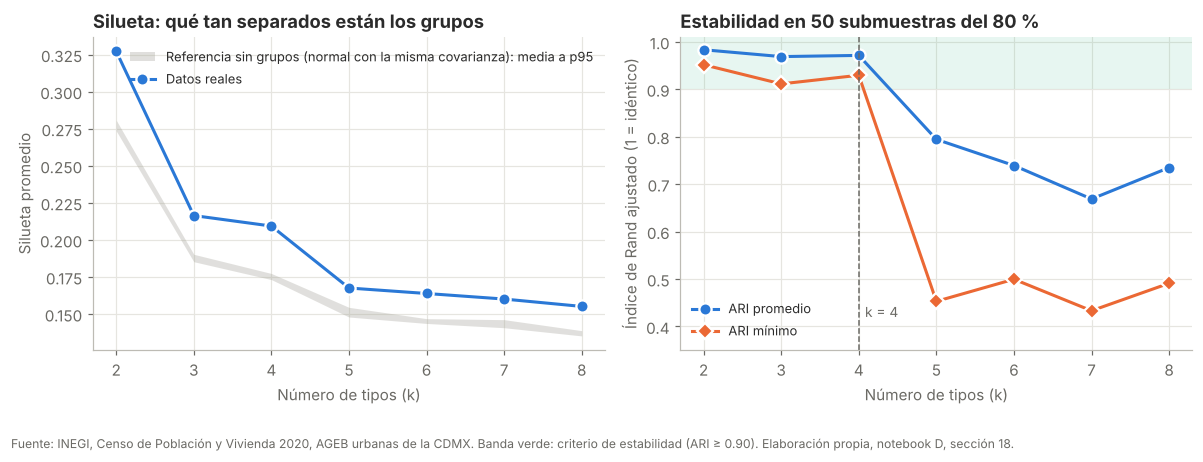

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.fill_between(sel_k.k, sel_k.silueta_nula_media, sel_k.silueta_nula_p95, color=GRIS, alpha=.35, lw=0,
                label='Referencia sin grupos (normal con la misma covarianza): media a p95')
a1.plot(sel_k.k, sel_k.silueta, color=AZUL, lw=2, marker='o', ms=8, mec='white', mew=1.5, label='Datos reales')
a1.set_title('Silueta: qué tan separados están los grupos'); a1.set_xlabel('Número de tipos (k)'); a1.set_ylabel('Silueta promedio')
a1.legend(loc='upper right', fontsize=8.5)
a2.axhspan(.9, 1.01, color=AQUA, alpha=.10, lw=0)
a2.plot(sel_k.k, sel_k.ari_promedio, color=AZUL, lw=2, marker='o', ms=8, mec='white', mew=1.5, label='ARI promedio')
a2.plot(sel_k.k, sel_k.ari_min, color=NARANJA, lw=2, marker='D', ms=7, mec='white', mew=1.5, label='ARI mínimo')
a2.axvline(K, color=TENUE, lw=1, ls='--'); a2.text(K + .08, .42, f'k = {K}', color=TENUE, fontsize=9)
a2.set_ylim(.35, 1.01); a2.set_title('Estabilidad en 50 submuestras del 80 %'); a2.set_xlabel('Número de tipos (k)')
a2.set_ylabel('Índice de Rand ajustado (1 = idéntico)'); a2.legend(loc='lower left', fontsize=8.5)
nota(fig, 'Fuente: INEGI, Censo de Población y Vivienda 2020, AGEB urbanas de la CDMX. Banda verde: criterio de estabilidad (ARI ≥ 0.90). '
          'Elaboración propia, notebook D, sección 18.')
plt.savefig(FIG / 'f11_tipologia_seleccion_k.png', dpi=150); plt.show()

## 5. Modelo final: k-means con k tipos

Se ajusta con 100 inicializaciones. Para que la numeración no dependa del azar, los tipos se **ordenan por su
posición en el CP1** (de menor a mayor escolaridad y conectividad), y los colores siguen ese orden en todas las
figuras. Los nombres se asignan después de ver el perfil, y se verifican con aserciones: si el perfil cambia al
re-ejecutar, el notebook falla en lugar de publicar un nombre equivocado.

In [9]:
modelo = kmeans(Z, K, n_init=100)
orden = np.argsort((modelo.cluster_centers_ @ pca.components_[0]))
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden, start=1)}
g['tipo'] = pd.Series(modelo.labels_).map(mapa).to_numpy()
centros_z = pd.DataFrame(modelo.cluster_centers_[orden], columns=VARS, index=range(1, K + 1))

# Margen de asignación: qué tan cerca está cada AGEB del segundo tipo más cercano (0 = justo en la frontera).
dist_c = np.sqrt(((Z[:, None, :] - modelo.cluster_centers_[None, :, :]) ** 2).sum(-1))
dist_c.sort(axis=1)
g['margen'] = (dist_c[:, 1] - dist_c[:, 0]) / dist_c[:, 1]
g['frontera'] = g.margen < 0.10
print(f"AGEB en frontera (margen < 10 %): {g.frontera.sum()} ({100*g.frontera.mean():.1f} %), con {g.loc[g.frontera, 'POBTOT'].sum():,} habitantes")

perfil = g.groupby('tipo').agg(n_ageb=('CVEGEO', 'size'), poblacion=('POBTOT', 'sum'), n_60=('n_60', 'sum'), n_disc=('n_disc', 'sum'),
                               **{f'med_{v}': (v, 'median') for v in VARS}, dist_oferta_km_med=('dist_oferta_km', 'median'))
perfil['pct_pob_cdmx'] = 100 * perfil.poblacion / total_entidad
sumas = g.groupby('tipo')[['n_60', 'POBTOT', 'viv_sin_int', 'viv', 'n_sinder']].sum()
perfil['pct_60_ponderado'] = 100 * sumas.n_60 / sumas.POBTOT
perfil['pct_viv_sin_int_ponderado'] = 100 * sumas.viv_sin_int / sumas.viv
perfil['pct_sinder_ponderado'] = 100 * sumas.n_sinder / sumas.POBTOT
perfil['pct_de_las_60_cdmx'] = 100 * perfil.n_60 / perfil.n_60.sum()
perfil.T.round(1)

AGEB en frontera (margen < 10 %): 300 (12.7 %), con 1,057,017 habitantes


tipo,1,2,3,4
n_ageb,637.0,912.0,474.0,348.0
poblacion,2825720.0,3899875.0,1108553.0,1293742.0
n_60,333858.0,640761.0,277483.0,234115.0
n_disc,153689.0,223124.0,63571.0,49765.0
med_pct_60,11.8,16.7,25.4,19.2
med_pct_disc,5.3,5.7,5.6,3.7
med_pct_0a14,22.4,17.6,12.0,12.4
med_prom_ocup,3.8,3.5,3.0,2.6
med_part_fem,52.7,55.0,52.9,63.1
med_pct_jef_f,35.3,40.7,43.5,41.9


In [10]:
if K == 4:
    NOMBRE = {1: 'Periferia joven con carencias', 2: 'Consolidada de transición', 3: 'Envejecida de escolaridad media-alta',
              4: 'Central de alta escolaridad'}
    m = perfil
    assert m.med_pct_0a14.idxmax() == 1 and m.med_pct_sin_int.idxmax() == 1 and m.med_pct_sinder.idxmax() == 1, 'Tipo 1 no es el más joven y con más carencias'
    assert m.med_pct_60.idxmax() == 3, 'Tipo 3 ya no es el más envejecido'
    assert m.med_graproes.idxmax() == 4 and m.med_part_fem.idxmax() == 4 and m.med_prom_ocup.idxmin() == 4, 'Tipo 4 ya no es el central de alta escolaridad'
    assert m.poblacion.idxmax() == 2, 'Tipo 2 ya no es el más poblado'
else:
    NOMBRE = {t: f'Tipo {t}' for t in range(1, K + 1)}
    print('ATENCIÓN: k distinto de 4; los nombres descriptivos no aplican y hay que revisar el perfil.')
g['tipo_nombre'] = g.tipo.map(NOMBRE)
COLOR = dict(zip(range(1, K + 1), [AZUL, NARANJA, AQUA, AMARILLO, '#e87ba4', '#008300'][:K]))
perfil.insert(0, 'nombre', perfil.index.map(NOMBRE))
perfil[['nombre', 'n_ageb', 'poblacion', 'pct_pob_cdmx', 'n_60', 'pct_de_las_60_cdmx', 'pct_60_ponderado', 'n_disc',
        'pct_sinder_ponderado', 'pct_viv_sin_int_ponderado', 'dist_oferta_km_med']].round(1)

,nombre,n_ageb,poblacion,pct_pob_cdmx,n_60,pct_de_las_60_cdmx,pct_60_ponderado,n_disc,pct_sinder_ponderado,pct_viv_sin_int_ponderado,dist_oferta_km_med
tipo,,,,,,,,,,,
1,Periferia joven con carencias,637,2825720,30.7,333858.0,22.5,11.8,153689.0,31.8,36.7,1.1
2,Consolidada de transición,912,3899875,42.3,640761.0,43.1,16.4,223124.0,27.3,25.4,0.9
3,Envejecida de escolaridad media-alta,474,1108553,12.0,277483.0,18.7,25.0,63571.0,23.1,13.4,0.7
4,Central de alta escolaridad,348,1293742,14.0,234115.0,15.8,18.1,49765.0,19.8,9.7,0.7


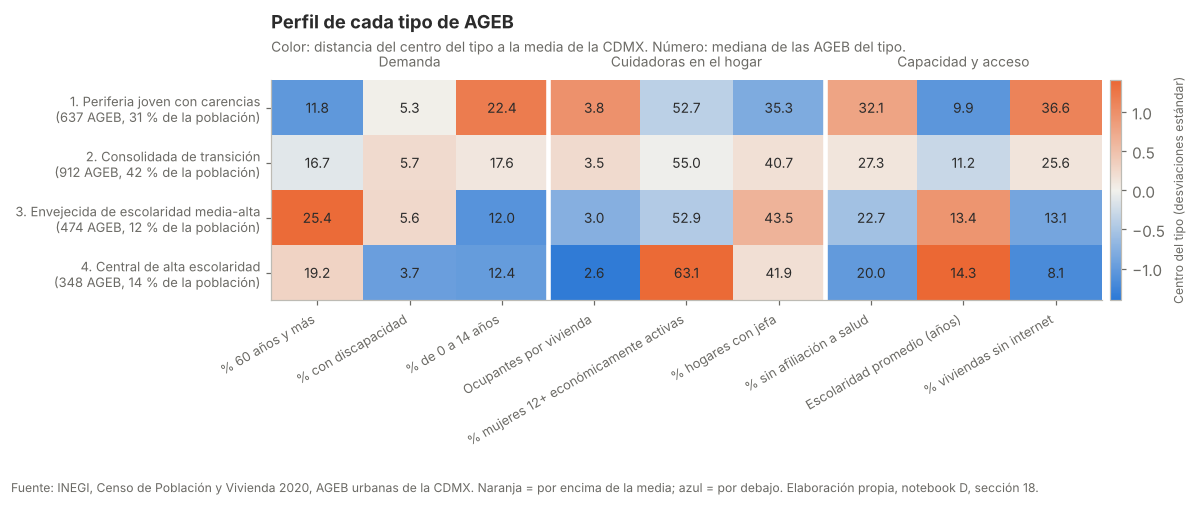

In [11]:
div = LinearSegmentedColormap.from_list('div', [AZUL, '#f2f1ec', NARANJA])
fig, ax = plt.subplots(figsize=(11, 4.6))
lim = np.abs(centros_z.to_numpy()).max()
im = ax.imshow(centros_z.to_numpy(), cmap=div, vmin=-lim, vmax=lim, aspect='auto')
for i, t in enumerate(centros_z.index):
    for j, v in enumerate(VARS):
        med = perfil.loc[t, f'med_{v}']
        ax.text(j, i, f'{med:.1f}', ha='center', va='center', fontsize=9, color=TINTA)
ax.set_xticks(range(len(VARS)), [ETQ[v] for v in VARS], rotation=30, ha='right', fontsize=8.5)
ax.set_yticks(range(K), [f'{t}. {NOMBRE[t]}\n({perfil.loc[t, "n_ageb"]} AGEB, {perfil.loc[t, "pct_pob_cdmx"]:.0f} % de la población)'
                         for t in centros_z.index], fontsize=8.5)
ax.grid(False)
for x in [2.5, 5.5]:
    ax.axvline(x, color='white', lw=3)
for x, b in [(1, 'Demanda'), (4, 'Cuidadoras en el hogar'), (7, 'Capacidad y acceso')]:
    ax.text(x, -0.75, b, ha='center', fontsize=9, color=TENUE)
cb = fig.colorbar(im, ax=ax, fraction=.025, pad=.01); cb.set_label('Centro del tipo (desviaciones estándar)', fontsize=8, color=TENUE)
ax.set_title('Perfil de cada tipo de AGEB', pad=34)
ax.text(0, 1.13, 'Color: distancia del centro del tipo a la media de la CDMX. Número: mediana de las AGEB del tipo.', transform=ax.transAxes, fontsize=9, color=TENUE)
nota(fig, 'Fuente: INEGI, Censo de Población y Vivienda 2020, AGEB urbanas de la CDMX. Naranja = por encima de la media; azul = por debajo. '
          'Elaboración propia, notebook D, sección 18.')
plt.savefig(FIG / 'f12_tipologia_perfiles.png', dpi=150); plt.show()

## 6. ¿Agrega algo el modelo? Comparación contra alternativas simples

La regla del proyecto exige comparar contra una alternativa simple. Aquí hay dos, ambas con el **mismo número de
grupos**:

- **Regla de dos cortes:** % de 60+ arriba o abajo de la mediana × % de viviendas sin internet arriba o abajo de la
  mediana. Es lo que un equipo haría a mano: demanda × capacidad.
- **Índice de una dimensión:** cuartiles (o k-tiles) del CP1. Es "un índice bien construido".

Criterios:

| Criterio | Qué mide | Por qué |
|---|---|---|
| R² sobre las 9 variables | Qué parte de la variación entre AGEB explica la partición | Homogeneidad dentro de cada tipo. **Ventaja de origen para k-means**, que optimiza justo esto |
| Estabilidad (ARI en 50 submuestras) | Si la partición cambia al cambiar las AGEB | Una tipología inestable no sirve para elegir sede |
| V de Cramér con el grado de rezago CONEVAL | Asociación con una clasificación oficial que no entró al modelo | Consistencia, **no** validez independiente: el CONEVAL construye su grado con indicadores del mismo Censo (salud, escolaridad, internet), así que la coincidencia es en parte circular |
| η² de `pct_limi` y de la distancia a la oferta | Separación en variables **no usadas** y de otra naturaleza | Lo más cercano a validez externa que permiten los datos |
| % de vecinos del mismo grupo | Coherencia espacial | Una tipología útil para elegir sede debería formar zonas, no un mosaico |

In [12]:
i_nb, j_nb = (lambda s: (s.index.to_numpy(), s.index_right.to_numpy()))(
    (lambda s: s[s.index != s.index_right])(gpd.sjoin(g[['geometry']], g[['geometry']], predicate='intersects')))
print(f'Pares de AGEB vecinas (comparten borde o vértice): {len(i_nb):,}')

def r2(lab, Zm=Z):
    w = sum(((Zm[lab == c] - Zm[lab == c].mean(0)) ** 2).sum() for c in np.unique(lab))
    return 1 - w / ((Zm - Zm.mean(0)) ** 2).sum()

def eta2(y, lab):
    y = np.asarray(y, float); m = y.mean()
    return sum((lab == c).sum() * (y[lab == c].mean() - m) ** 2 for c in np.unique(lab)) / ((y - m) ** 2).sum()

def cramer(lab, otra):
    t = pd.crosstab(lab, otra); c2 = chi2_contingency(t)[0]
    return np.sqrt(c2 / (t.to_numpy().sum() * (min(t.shape) - 1)))

def regla_cortes(df):
    return lambda dd: ((dd.pct_60 > df.pct_60.median()).astype(int) * 2 + (dd.pct_sin_int > df.pct_sin_int.median()).astype(int)).to_numpy()

def regla_indice(df_cp1, k):
    cortes = np.quantile(df_cp1, np.linspace(0, 1, k + 1)[1:-1])
    return lambda cp: np.digitize(cp, cortes)

def estab_regla(fabrica, B=50):
    ref = fabrica(np.arange(len(g)))
    r = np.random.default_rng(SEMILLA); out = []
    for b in range(B):
        idx = r.choice(len(g), int(.8 * len(g)), replace=False)
        out.append(adjusted_rand_score(ref, fabrica(idx)))
    return np.array(out)

alternativas = {
    f'Regla 60+ × internet ({4} grupos)': (regla_cortes(g)(g), lambda idx: regla_cortes(g.iloc[idx])(g)),
    f'Índice CP1 en {K} grupos': (regla_indice(g.cp1, K)(g.cp1), lambda idx: regla_indice(g.cp1.iloc[idx], K)(g.cp1)),
    f'k-means, {K} tipos (modelo)': (g.tipo.to_numpy(), None),
}
filas = []
for nombre, (lab, fab) in alternativas.items():
    ari = estabilidad(Z, K) if fab is None else estab_regla(fab)
    filas.append(dict(particion=nombre, grupos=len(np.unique(lab)), r2_9_variables=r2(lab), ari_promedio=ari.mean(), ari_min=ari.min(),
                      cramer_v_rezago_coneval=cramer(lab, g.grs.fillna('sin dato')), eta2_pct_limitacion=eta2(g.pct_limi, lab),
                      eta2_log_distancia_oferta=eta2(np.log(g.dist_oferta_km), lab), vecinos_mismo_grupo=(lab[i_nb] == lab[j_nb]).mean()))
comp = pd.DataFrame(filas)
comp.round(3)

Pares de AGEB vecinas (comparten borde o vértice): 13,746


,particion,grupos,r2_9_variables,ari_promedio,ari_min,cramer_v_rezago_coneval,eta2_pct_limitacion,eta2_log_distancia_oferta,vecinos_mismo_grupo
0,Regla 60+ × internet (4 grupos),4,0.414,0.981,0.942,0.491,0.006,0.060,0.638
1,Índice CP1 en 4 grupos,4,0.493,0.968,0.900,0.551,0.013,0.054,0.621
2,"k-means, 4 tipos (modelo)",4,0.529,0.971,0.929,0.567,0.047,0.058,0.656


## 7. Robustez: ¿los tipos sobreviven a otras decisiones razonables?

Cada variante cambia **una** decisión y se compara su partición con la del modelo final (ARI; 1 = idéntica).
Un ARI alto significa que los tipos no dependen de esa decisión.

In [13]:
def ajusta(Zm, k=K, peso=None):
    return kmeans(Zm, k, n_init=50, peso=peso).labels_

coneval_full = None
with zipfile.ZipFile(DATOS / 'coneval_irs' / 'grs_ageb_2020.csv.zip') as z:
    coneval_full = pd.read_csv(z.open('grs_ageb_2020.csv'), dtype=str)
coneval_full = coneval_full[coneval_full.clave_entidad == '9'].rename(columns={'folio_ageb': 'CVEGEO'})
cap_con = g[['CVEGEO']].merge(coneval_full[['CVEGEO', 'i_sdsalud', 'i_edbasinc', 'i_nointernet']], on='CVEGEO', how='left')
cap_con = cap_con[['i_sdsalud', 'i_edbasinc', 'i_nointernet']].apply(pd.to_numeric, errors='coerce')
ok_con = cap_con.notna().all(axis=1).to_numpy()
X_con = np.c_[g[VARS[:6]].to_numpy(float), cap_con.to_numpy(float)][ok_con]

ref = g.tipo.to_numpy()
variantes = [
    ('Ponderado por población (cada persona pesa igual, no cada AGEB)', ajusta(Z, peso=g.POBTOT.to_numpy(float)), slice(None)),
    ('Escalamiento robusto (mediana y rango intercuartil)', ajusta(RobustScaler().fit_transform(X)), slice(None)),
    ('Sin % de viviendas sin internet', ajusta(StandardScaler().fit_transform(g[[v for v in VARS if v != 'pct_sin_int']])), slice(None)),
    ('Sin el bloque de cuidadoras en el hogar', ajusta(StandardScaler().fit_transform(g[[v for v in VARS if BLOQUE[v] != 'Cuidadoras']])), slice(None)),
    ('Capacidad medida con indicadores CONEVAL en lugar del Censo', ajusta(StandardScaler().fit_transform(X_con)), ok_con),
    ('Sobre los 4 primeros componentes principales', ajusta(PCA(4, random_state=SEMILLA).fit_transform(Z)), slice(None)),
    ('Ward jerárquico (otro algoritmo)', AgglomerativeClustering(n_clusters=K).fit_predict(Z), slice(None)),
    ('Mezcla gaussiana, covarianza completa (otro algoritmo)', GaussianMixture(K, covariance_type='full', n_init=5, random_state=SEMILLA).fit(Z).predict(Z), slice(None)),
]
robustez = pd.DataFrame([dict(variante=n, ari_vs_modelo=adjusted_rand_score(ref[m], lab), n_ageb=len(lab)) for n, lab, m in variantes])
bic = pd.DataFrame({'k': list(KS), 'bic_mezcla_gaussiana': [GaussianMixture(k, covariance_type='full', n_init=3, random_state=SEMILLA).fit(Z).bic(Z) for k in KS]})
display(robustez.round(3))
print('BIC de la mezcla gaussiana por k (menor es mejor): mínimo en k =', int(bic.loc[bic.bic_mezcla_gaussiana.idxmin(), 'k']))
bic.round(0).T

,variante,ari_vs_modelo,n_ageb
0,"Ponderado por población (cada persona pesa igual, no cada AGEB)",0.911,2371
1,Escalamiento robusto (mediana y rango intercuartil),0.876,2371
2,Sin % de viviendas sin internet,0.874,2371
3,Sin el bloque de cuidadoras en el hogar,0.702,2371
4,Capacidad medida con indicadores CONEVAL en lugar del Censo,0.928,2371
5,Sobre los 4 primeros componentes principales,0.961,2371
6,Ward jerárquico (otro algoritmo),0.526,2371
7,"Mezcla gaussiana, covarianza completa (otro algoritmo)",0.338,2371


BIC de la mezcla gaussiana por k (menor es mejor): mínimo en k = 6


,0,1,2,3,4,5,6
k,2.0,3.0,4.0,5.0,6.0,7.0,8.0
bic_mezcla_gaussiana,42527.0,39695.0,38753.0,38356.0,38252.0,38274.0,38330.0


## 8. Territorio: coherencia espacial y transferencia entre alcaldías

Dos pruebas:

- **Vecindad.** ¿Qué proporción de pares de AGEB vecinas caen en el mismo tipo? Se compara contra 999 permutaciones
  aleatorias de las etiquetas (mismo tamaño de cada tipo, sin geografía).
- **Dejar fuera una alcaldía.** Se ajusta el modelo sin las AGEB de una alcaldía y se clasifican esas AGEB con el
  modelo resultante. Si la asignación coincide con la del modelo completo, la tipología **se transfiere** a zonas que
  no vio. Esta prueba es más exigente que el bootstrap de la sección 4, que trata a las AGEB como independientes
  aunque no lo son.

In [14]:
obs = (ref[i_nb] == ref[j_nb]).mean()
perm = np.array([(p[i_nb] == p[j_nb]).mean() for p in (rng.permutation(ref) for _ in range(999))])
print(f'Vecinos del mismo tipo: {100*obs:.1f} % | al azar: {100*perm.mean():.1f} % (máximo en 999 permutaciones: {100*perm.max():.1f} %)')

filas = []
for alc in sorted(g.alcaldia.unique()):
    fuera = (g.alcaldia == alc).to_numpy()
    sc = StandardScaler().fit(X[~fuera]); m = kmeans(sc.transform(X[~fuera]), K, n_init=50)
    # Empareja los tipos del modelo parcial con los del modelo completo por cercanía de centros (en escala original).
    c_full = np.array([X[ref == t].mean(0) for t in range(1, K + 1)])
    c_part = sc.inverse_transform(m.cluster_centers_)
    costo = ((c_part[:, None, :] - c_full[None, :, :]) ** 2 / X.var(0)).sum(-1)
    fila, col = linear_sum_assignment(costo); emp = dict(zip(fila, col + 1))
    pred = np.vectorize(emp.get)(m.predict(sc.transform(X[fuera])))
    filas.append(dict(alcaldia=alc, n_ageb=fuera.sum(), coincidencia_pct=100 * (pred == ref[fuera]).mean()))
loao = pd.DataFrame(filas)
print(f'Coincidencia ponderada por número de AGEB: {np.average(loao.coincidencia_pct, weights=loao.n_ageb):.1f} %')
loao.round(1)

Vecinos del mismo tipo: 65.6 % | al azar: 28.1 % (máximo en 999 permutaciones: 29.9 %)


Coincidencia ponderada por número de AGEB: 97.8 %


,alcaldia,n_ageb,coincidencia_pct
0,Azcapotzalco,102,97.1
1,Benito Juárez,102,99.0
2,Coyoacán,155,97.4
3,Cuajimalpa de Morelos,31,100.0
4,Cuauhtémoc,152,95.4
5,Gustavo A. Madero,299,100.0
6,Iztacalco,107,99.1
7,Iztapalapa,452,97.6
8,La Magdalena Contreras,52,100.0
9,Miguel Hidalgo,113,97.3


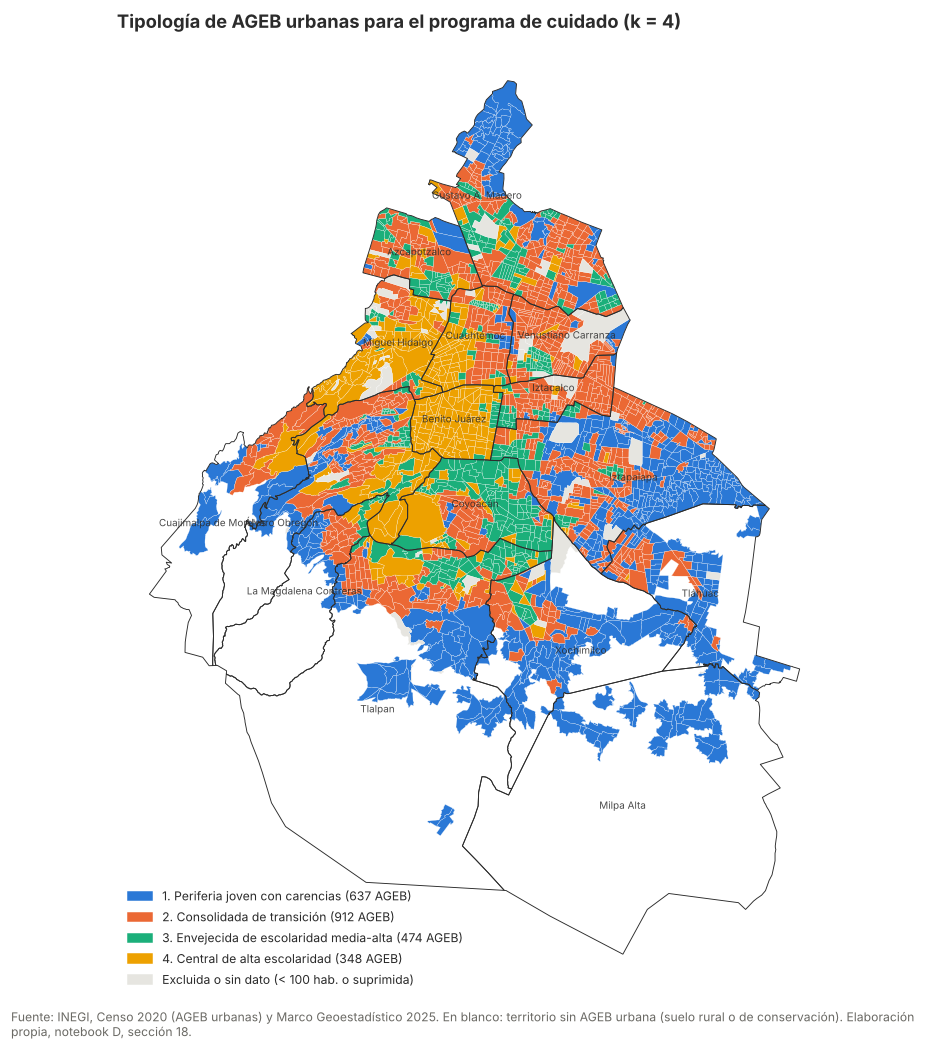

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 9.6))
for t in range(1, K + 1):
    g[g.tipo == t].plot(ax=ax, color=COLOR[t], edgecolor='white', linewidth=.15)
alc_geo.boundary.plot(ax=ax, color=TINTA, linewidth=.6)
geo[~geo.CVEGEO.isin(g.CVEGEO)].plot(ax=ax, color='#e6e5e0', edgecolor='white', linewidth=.15)
for _, r in alc_geo.iterrows():
    p = r.geometry.representative_point(); ax.text(p.x, p.y, r.NOMGEO, fontsize=6.5, color=TINTA, ha='center', alpha=.85)
ax.set_axis_off(); ax.set_aspect('equal')
ax.legend(handles=[Patch(color=COLOR[t], label=f'{t}. {NOMBRE[t]} ({perfil.loc[t, "n_ageb"]} AGEB)') for t in range(1, K + 1)] +
          [Patch(color='#e6e5e0', label='Excluida o sin dato (< 100 hab. o suprimida)')], loc='lower left', fontsize=8, frameon=False)
ax.set_title(f'Tipología de AGEB urbanas para el programa de cuidado (k = {K})', loc='left')
nota(fig, 'Fuente: INEGI, Censo 2020 (AGEB urbanas) y Marco Geoestadístico 2025. En blanco: territorio sin AGEB urbana (suelo rural o de conservación). '
          'Elaboración propia, notebook D, sección 18.')
plt.savefig(FIG / 'f13_tipologia_mapa.png', dpi=150); plt.show()

## 9. Capa de decisión: canal de la app y brechas de oferta

Aquí la tipología se usa para la decisión. Las cifras son **conteos censales** (personas y viviendas), no
porcentajes por AGEB, porque el piloto atiende personas.

**Brecha de oferta (exploratoria).** Se marca una AGEB como brecha si está en el cuartil superior de personas de 60+
**y** en el cuartil superior de distancia a la oferta núcleo. Los umbrales son una convención, no un estándar; por
eso se reporta también con terciles. La distancia es en línea recta y la oferta no incluye capacidad ni precio: una
AGEB "sin brecha" puede tener un asilo cercano que nadie puede pagar.

In [16]:
def brecha(q):
    return (g.n_60 >= g.n_60.quantile(q)) & (g.dist_oferta_km >= g.dist_oferta_km.quantile(q))

g['brecha_q75'] = brecha(.75); g['brecha_q67'] = brecha(2 / 3)
decision = g.groupby('tipo').agg(nombre=('tipo_nombre', 'first'), n_ageb=('CVEGEO', 'size'), poblacion=('POBTOT', 'sum'), personas_60=('n_60', 'sum'),
                                  personas_discapacidad=('n_disc', 'sum'), viviendas=('viv', 'sum'), viviendas_sin_internet=('viv_sin_int', 'sum'),
                                  dist_oferta_km_mediana=('dist_oferta_km', 'median'), ageb_brecha_q75=('brecha_q75', 'sum'),
                                  ageb_brecha_q67=('brecha_q67', 'sum'))
decision['pct_viviendas_sin_internet'] = 100 * decision.viviendas_sin_internet / decision.viviendas
decision['pct_60_en_ageb_a_mas_de_1km'] = g.assign(lejos=g.n_60 * (g.dist_oferta_km > 1)).groupby('tipo').lejos.sum() / decision.personas_60 * 100
decision['personas_60_en_brecha_q75'] = g[g.brecha_q75].groupby('tipo').n_60.sum().reindex(decision.index, fill_value=0)
tot = decision.select_dtypes('number').sum()
print(f"Viviendas sin internet en las AGEB del modelo: {int(tot.viviendas_sin_internet):,} de {int(tot.viviendas):,} "
      f"({100*tot.viviendas_sin_internet/tot.viviendas:.1f} %)")
decision.round(1)

Viviendas sin internet en las AGEB del modelo: 655,725 de 2,733,228 (24.0 %)


,nombre,n_ageb,poblacion,personas_60,personas_discapacidad,viviendas,viviendas_sin_internet,dist_oferta_km_mediana,ageb_brecha_q75,ageb_brecha_q67,pct_viviendas_sin_internet,pct_60_en_ageb_a_mas_de_1km,personas_60_en_brecha_q75
tipo,,,,,,,,,,,,,
1,Periferia joven con carencias,637,2825720,333858.0,153689.0,735640.0,269617.0,1.1,49,72,36.7,54.6,51127.0
2,Consolidada de transición,912,3899875,640761.0,223124.0,1135542.0,288677.0,0.9,80,144,25.4,46.2,87806.0
3,Envejecida de escolaridad media-alta,474,1108553,277483.0,63571.0,369826.0,49601.0,0.7,10,20,13.4,26.1,10663.0
4,Central de alta escolaridad,348,1293742,234115.0,49765.0,492220.0,47830.0,0.7,12,21,9.7,28.9,14758.0


In [17]:
por_alcaldia = (g.pivot_table(index='alcaldia', columns='tipo', values='POBTOT', aggfunc='sum', fill_value=0)
                .pipe(lambda t: 100 * t.div(t.sum(axis=1), axis=0)).round(1).rename(columns=lambda t: f'pct_pob_tipo_{t}'))
por_alcaldia['ageb_brecha_q75'] = g.groupby('alcaldia').brecha_q75.sum()
por_alcaldia['personas_60_en_brecha_q75'] = g[g.brecha_q75].groupby('alcaldia').n_60.sum().reindex(por_alcaldia.index, fill_value=0)
por_alcaldia.sort_values('personas_60_en_brecha_q75', ascending=False)

tipo,pct_pob_tipo_1,pct_pob_tipo_2,pct_pob_tipo_3,pct_pob_tipo_4,ageb_brecha_q75,personas_60_en_brecha_q75
alcaldia,,,,,,
Azcapotzalco,1.3,60.0,24.5,14.2,23,25358.0
Iztapalapa,55.5,37.8,5.2,1.5,22,21789.0
Cuauhtémoc,6.1,50.8,9.1,34.0,13,16439.0
Iztacalco,5.1,80.5,11.2,3.2,15,15539.0
Venustiano Carranza,7.6,77.4,10.1,4.9,12,12437.0
Tlalpan,38.9,36.0,18.1,7.0,13,12353.0
Coyoacán,7.4,37.5,44.4,10.7,8,10893.0
Álvaro Obregón,30.0,41.9,10.8,17.3,9,10257.0
Cuajimalpa de Morelos,40.5,47.2,0.0,12.3,8,9897.0


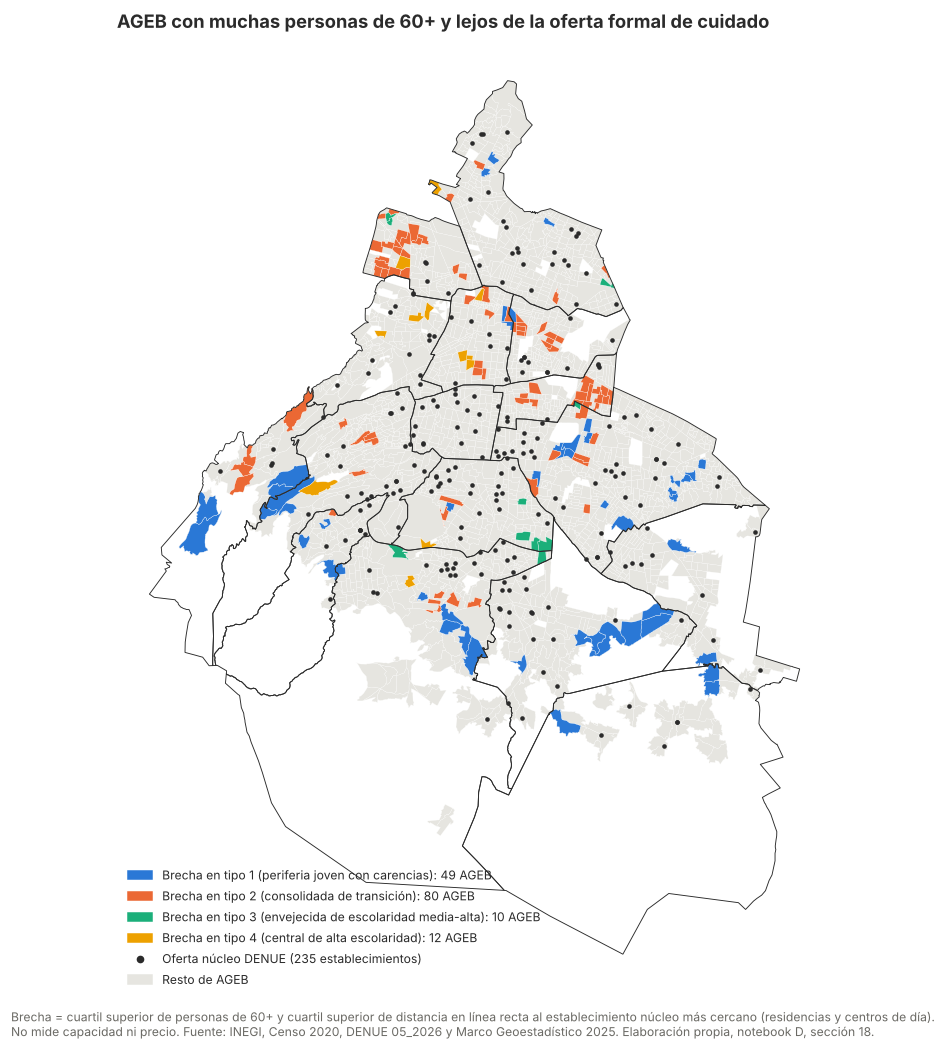

In [18]:
fig, ax = plt.subplots(figsize=(8.6, 9.6))
g.plot(ax=ax, color='#e6e5e0', edgecolor='white', linewidth=.15)
for t in range(1, K + 1):
    sub = g[g.brecha_q75 & (g.tipo == t)]
    if len(sub):
        sub.plot(ax=ax, color=COLOR[t], edgecolor='white', linewidth=.2)
alc_geo.boundary.plot(ax=ax, color=TINTA, linewidth=.6)
ax.scatter(den.geometry.x, den.geometry.y, s=9, color=TINTA, marker='o', lw=0, zorder=5)
ax.set_axis_off(); ax.set_aspect('equal')
ax.legend(handles=[Patch(color=COLOR[t], label=f'Brecha en tipo {t} ({NOMBRE[t].lower()}): {int(decision.loc[t, "ageb_brecha_q75"])} AGEB')
                   for t in range(1, K + 1)] +
          [plt.Line2D([], [], color=TINTA, marker='o', lw=0, ms=4, label=f'Oferta núcleo DENUE ({len(den)} establecimientos)'),
           Patch(color='#e6e5e0', label='Resto de AGEB')], loc='lower left', fontsize=8, frameon=False)
ax.set_title('AGEB con muchas personas de 60+ y lejos de la oferta formal de cuidado', loc='left')
nota(fig, 'Brecha = cuartil superior de personas de 60+ y cuartil superior de distancia en línea recta al establecimiento núcleo más cercano '
          '(residencias y centros de día). No mide capacidad ni precio. Fuente: INEGI, Censo 2020, DENUE 05_2026 y Marco Geoestadístico 2025. '
          'Elaboración propia, notebook D, sección 18.')
plt.savefig(FIG / 'f14_tipologia_brecha_oferta.png', dpi=150); plt.show()

## 10. Guardar resultados

`18_tipologia_ageb.csv` contiene una fila por AGEB con su tipo. Los contornos simplificados y los puntos de la oferta núcleo
(DENUE, dato público de establecimientos) se guardan para el mapa del Observatorio. Son **agregados censales públicos**: no hay datos
personales. El riesgo de reidentificación aparece si después se cruza esta tabla con datos individuales del piloto
(por ejemplo, "persona cuidadora de la AGEB X con tal condición"): eso no se hace en el repositorio (ver sección 11).

In [19]:
cols = ['CVEGEO', 'alcaldia', 'tipo', 'tipo_nombre', 'POBTOT', 'n_60', 'n_disc'] + VARS + ['cp1', 'margen', 'frontera', 'grs', 'dist_oferta_km', 'n_oferta_2km', 'brecha_q75', 'brecha_q67']
g[cols].rename(columns={'POBTOT': 'poblacion', 'grs': 'grado_rezago_coneval'}).to_csv(OUT / '18_tipologia_ageb.csv', index=False, encoding='utf-8-sig')
perfil.to_csv(OUT / '18_tipologia_perfiles.csv', encoding='utf-8-sig')
sel_k.to_csv(OUT / '18_tipologia_seleccion_k.csv', index=False, encoding='utf-8-sig')
comp.to_csv(OUT / '18_tipologia_comparacion.csv', index=False, encoding='utf-8-sig')
robustez.to_csv(OUT / '18_tipologia_robustez.csv', index=False, encoding='utf-8-sig')
loao.to_csv(OUT / '18_tipologia_dejar_fuera_alcaldia.csv', index=False, encoding='utf-8-sig')
decision.to_csv(OUT / '18_tipologia_decision.csv', encoding='utf-8-sig')
por_alcaldia.to_csv(OUT / '18_tipologia_por_alcaldia.csv', encoding='utf-8-sig')
calidad.to_csv(OUT / '18_tipologia_calidad.csv', index=False, encoding='utf-8-sig')
# Contornos simplificados (tolerancia 15 m) para el mapa del Observatorio: AGEB del modelo y alcaldías, en lon/lat con 5 decimales.
import json
from shapely.geometry import mapping
def _redondea(geom):
    m = mapping(geom)
    def r(c):
        return [round(c[0], 5), round(c[1], 5)] if isinstance(c[0], float) else [r(x) for x in c]
    return {'type': m['type'], 'coordinates': r(m['coordinates'])}
capas = [('ageb', row.CVEGEO, row.geometry) for row in g[['CVEGEO', 'geometry']].itertuples()] + \
        [('alcaldia', row.NOMGEO, row.geometry) for row in alc_geo[['NOMGEO', 'geometry']].itertuples()]
simpl = gpd.GeoSeries([c[2] for c in capas], crs=geo.crs).simplify(15, preserve_topology=True).to_crs(4326)
fc = {'type': 'FeatureCollection', 'features': [{'type': 'Feature', 'properties': {'capa': c[0], 'id': c[1]}, 'geometry': _redondea(gm)}
                                                for c, gm in zip(capas, simpl)]}
(OUT / '18_tipologia_contornos.geojson').write_text(json.dumps(fc, ensure_ascii=False, separators=(',', ':')), encoding='utf-8')
den.to_crs(4326).assign(lon=lambda x: x.geometry.x.round(5), lat=lambda x: x.geometry.y.round(5))[['codigo_act', 'nombre_act', 'lon', 'lat']] \
   .to_csv(OUT / '18_oferta_nucleo_puntos.csv', index=False, encoding='utf-8-sig')
print('Guardados 9 archivos 18_tipologia_*.csv, los contornos (18_tipologia_contornos.geojson) y la oferta núcleo '
      '(18_oferta_nucleo_puntos.csv) en resultados/, y las figuras f11 a f14 en figuras/')

Guardados 9 archivos 18_tipologia_*.csv, los contornos (18_tipologia_contornos.geojson) y la oferta núcleo (18_oferta_nucleo_puntos.csv) en resultados/, y las figuras f11 a f14 en figuras/


## 11. Lectura

Todas las cifras salen de `resultados/18_tipologia_*.csv`. Universo: 2,371 AGEB urbanas de la CDMX con 9.13 millones
de habitantes (99.1 % de la población, Censo 2020).

**0. Validación.** El archivo del Censo coincide con el SHA-256 registrado. Los 235 establecimientos núcleo
reproducen la sección 01. Solo 2 AGEB del modelo no tienen polígono en el Marco 2025.

**1. La CDMX es un continuo, no un conjunto de tipos naturales.**
- Una sola dimensión explica el 53 % de la variación: el gradiente de transición demográfica y socioeconómica (CP1).
- La proporción de 60+ y la escolaridad se mueven juntas (r = 0.69). En términos **relativos**, las zonas más
  envejecidas son las de mayor capacidad de pago.
- La silueta real (0.21 con k = 4) supera a la de una referencia sin grupos con la misma covarianza (p95 = 0.18),
  pero por poco. Ward y la mezcla gaussiana cortan distinto (ARI 0.53 y 0.34).
- **Conclusión:** los 4 tipos son una **partición estable y útil** de un continuo, no "cuatro clases de zonas que
  descubrimos". En la defensa hay que decirlo así.

**2. k = 4 es la partición más detallada que se sostiene.** k de 2 a 4 son estables (ARI promedio ≥ 0.97). Con
k ≥ 5 la asignación cambia mucho entre submuestras (ARI mínimo entre 0.43 y 0.50). El BIC de la mezcla gaussiana prefiere
k = 6, pero esa partición no es estable con k-means y no se usa.

**3. Contra las alternativas simples, el modelo agrega poco, pero algo concreto.**
- R² sobre las 9 variables: 0.53 el modelo, 0.49 el índice CP1 y 0.41 la regla 60+ × internet. Esta ventaja está
  inflada a favor del modelo, que optimiza justo esa medida.
- Las tres particiones son igual de estables (ARI ≥ 0.97) y similares en distancia a la oferta y en coherencia
  espacial.
- **Lo que el índice no hace y el modelo sí:** separar el tipo 3 (más envejecido, discapacidad en la media) del tipo 4
  (central, la menor discapacidad, alta participación laboral femenina). El índice los mezcla porque los dos están en
  el extremo alto del CP1. Por eso el modelo separa mejor la limitación, una variable que no usó: η² = 0.047 contra
  0.013 y 0.006. Es poco en absoluto.
- **Conclusión:** si al equipo le basta un gradiente, el índice CP1 es suficiente y más fácil de explicar. Es un
  resultado válido.

**4. Robustez.** Los tipos casi no cambian si se pondera por población, se usa un escalamiento robusto, se quita
internet, se mide la capacidad con indicadores del CONEVAL o se trabaja sobre 4 componentes (ARI de 0.87 a 0.96).
Sí cambian al quitar el bloque de cuidadoras (0.70) o al cambiar de algoritmo (punto 1).

**5. Territorio.**
- El 65.6 % de los pares de AGEB vecinas son del mismo tipo, contra 28.1 % al azar. Los tipos forman zonas, no un
  mosaico.
- Al dejar fuera cada alcaldía, el modelo clasifica sus AGEB igual que el modelo completo en el 97.8 % de los casos.
- El 12.7 % de las AGEB (1.06 millones de habitantes) está en la frontera entre dos tipos (margen < 10 %).

**6. Para la decisión del piloto.**
- **Dónde están las personas de 60+:** 43.1 % en el tipo 2 (consolidada de transición), 22.5 % en el tipo 1 (periferia
  joven con carencias) y 34.5 % en los tipos 3 y 4. El tipo más envejecido en porcentaje (3) concentra solo el
  18.7 %.
- **Canal de la app:** el 36.7 % de las viviendas del tipo 1 y el 25.4 % del tipo 2 no tienen internet (269,617 y
  288,677 viviendas). Un piloto que solo use la app en esas zonas deja fuera a una de cada tres o cuatro viviendas.
  **El programa necesita un canal sin internet** (teléfono o presencial), o debe declarar esa exclusión.
- **Lejanía de la oferta formal:** el 54.6 % de las personas de 60+ del tipo 1 y el 46.2 % del tipo 2 viven en AGEB a
  más de 1 km en línea recta de una residencia o centro de día. En los tipos 3 y 4 es el 26 % al 29 %.
- **Brechas (exploratorio):** 151 AGEB con 164,354 personas de 60+ están en el cuartil alto de personas de 60+ y en el
  cuartil alto de distancia; 80 de ellas son del tipo 2. Con terciles son 257. Por alcaldía, Azcapotzalco (23 AGEB) e
  Iztapalapa (22) concentran más personas de 60+ en brecha.
- **Propuesta para discutir en equipo:**
  - Con una sola sede, el tipo 2 representa a la mayor parte de las personas de 60+ y queda en medio del gradiente.
  - Sus resultados **no se pueden extrapolar** al tipo 1, que tiene menos conectividad y menos capacidad de pago y
    donde el precio pesaría distinto, ni a los tipos 3 y 4.
  - Con dos sedes, conviene sumar una del tipo 1.
  - Si la sede candidata está en una AGEB de frontera, hay que revisarla contra los dos tipos.

**Condiciones bajo las cuales el modelo deja de servir o no debe usarse:**
1. **Para hablar de personas.** Es una tipología de zonas. Que una AGEB sea del tipo 1 no dice nada de una cuidadora
   que viva ahí (falacia ecológica). Tampoco permite cruzarlo con el modelo 11 para decir que "en el tipo 1 hay más
   daño": la ENASIC no tiene AGEB.
2. **Con otro corte del Censo.** Los datos son de marzo de 2020 (inicio de la pandemia). Con el conteo de 2025 o el
   censo de 2030, hay que re-ajustarlo, no reutilizar los centros.
3. **Para medir acceso real.** La distancia es en línea recta a 235 establecimientos núcleo, sin capacidad, precio ni
   transporte. "Sin brecha" no significa "con acceso".
4. **Como validación definitiva.** No hay una variable de resultado de cuidado por AGEB con la cual validar. La
   coincidencia con el grado de rezago del CONEVAL (V de Cramér = 0.57) es en parte circular: comparte indicadores del
   Censo.
5. **Con otro algoritmo o con k ≠ 4.** Los nombres de los tipos solo valen para este ajuste. El notebook falla a
   propósito si el perfil cambia.
6. **Discapacidad.** `PCON_DISC` es de cualquier edad. La discapacidad casi no estructura la tipología (pesa en el
   CP2), así que la tipología no sustituye un análisis de discapacidad.

**Protección de datos.** Todo son agregados censales públicos por AGEB. El riesgo aparece si en el piloto se junta
la AGEB de residencia con datos individuales sensibles (condición de salud, dependencia) en AGEB pequeñas. Esa
combinación queda en poder de la institución receptora y no entra al repositorio, según las reglas del proyecto.
Qué se puede pedir en el registro lo decide el dictamen de Leyes.

**Pendiente de doble revisión** (la persona que revise no debe ser quien produjo el notebook).